In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv('../data/raw/Telco-Customer-Churn_unprocessed.csv')
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [3]:
df['customerID'].duplicated().sum()

np.int64(0)

# Cleaning

In [4]:
df.drop(columns=['customerID'], inplace=True)

In [5]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [6]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [7]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [8]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [11]:
#changing total charges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [12]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int) # converts true/false to 1/0 for all boolean cols

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [14]:
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [15]:
df.groupby('Churn')['InternetService'].value_counts(normalize=True) * 100

Churn  InternetService
No     DSL                37.920371
       Fiber optic        34.770004
       No                 27.309625
Yes    Fiber optic        69.395399
       DSL                24.558587
       No                  6.046014
Name: proportion, dtype: float64

In [16]:
# from above we can observe that user using Fibre optic internet service has churned the most

In [17]:
df.describe(include='all')

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7032.000000,7043
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2283.300441,NaN
std,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.771362,NaN
min,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,401.450000,NaN
50%,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN


In [18]:
# mask=df['Partner'] == 'Yes'
df.groupby('Churn')['Partner'].value_counts(normalize=True) * 100

Churn  Partner
No     Yes        52.821801
       No         47.178199
Yes    No         64.205457
       Yes        35.794543
Name: proportion, dtype: float64

In [19]:
binary_cols = [col for col in df.columns if df[col].nunique() == 2]
binary_cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'PaperlessBilling',
 'Churn']

# Binary Encoding


In [20]:
#binary categorial column{2 unique values}
binary_cols=[
    'gender','Partner','Dependents','PhoneService','PaperlessBilling','Churn'
]

#Map Yes/No and Male/Female to 0/1
df[binary_cols] =df[binary_cols].replace({
    'Yes':1,'No':0,
    'Male':1,'Female':0
})

C:\Users\PC\AppData\Local\Temp\ipykernel_20112\4144677239.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[binary_cols] =df[binary_cols].replace({


In [21]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0


# ONE HOT ENCODING

In [22]:
#categorical column with more than 2 unique values
multi_cat_col=[col for col in df.columns if df[col].nunique() > 2 and df[col].dtype == 'object']
multi_cat_col

['MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod']

In [23]:
#one hot encoding 
df= pd.get_dummies(df, columns= multi_cat_col,drop_first=True)

In [24]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,False,False,False,True,False,False,False,True


# Collinearity check

In [25]:
import seaborn as sns

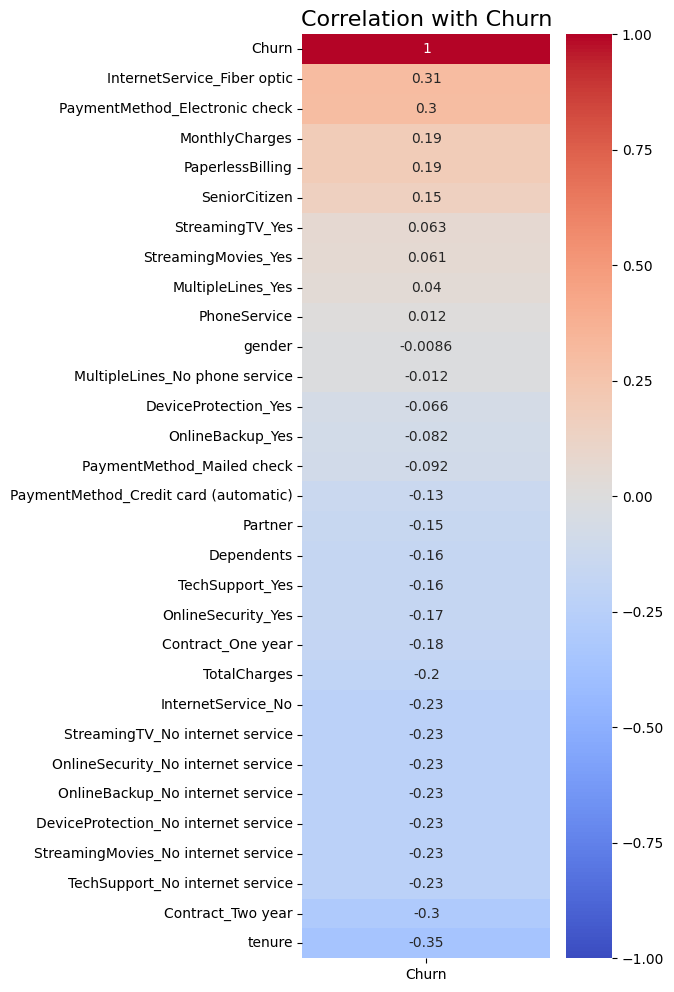

In [26]:
#Computing correlation for numerical column
corr_matrix= df.corr(numeric_only=True)

#we are trying to find strong correlation with churn
churn_corr= corr_matrix[['Churn']].sort_values(by='Churn', ascending=False)

#Plot heatmap for correlation
plt.figure(figsize=(4,12))
sns.heatmap(churn_corr, annot=True, cmap='coolwarm', vmin= -1, vmax=1)
plt.title('Correlation with Churn', fontsize=16)
plt.show()

#### from above the user using fibre optic internet service has churned the most and also the user with month to month contract has churned the most.
#### on with 2 year contract have churned the least and stay with the company for a long time. Also the user with electronic check payment method has churned the most.


#### negative correlation with churn(less likely to churn)
#### ->tenure(-0.35)
#### -> Contract_Two year(-0.30)
#### ->Contract_One year(-0.18)

#### positive correlation with churn(morelikely to churn)
#### -> internetService_Fiber optic(0.31)
#### -> PaymentMethod_Electronic check(+0.30)


## for multicollinearity

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Select numerical input features
# Do NOT include target variable or customerID
X = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].copy()


# 3. Handle missing values for this diagnostic
X = X.fillna(X.median())

# 4. Calculate VIF
vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

# 5. Sort VIF values
vif_data = vif_data.sort_values(
    by='VIF', ascending=False
)

print(vif_data)


          Feature       VIF
2    TotalCharges  9.411871
0          tenure  5.771901
1  MonthlyCharges  3.278781
3   SeniorCitizen  1.054622


#### Multicollinearity Analysis:

##### 1. TotalCharges has the highest VIF (9.41),
   indicating a potential multicollinearity issue.

##### 2. tenure has a VIF of 5.77, suggesting
   moderate multicollinearity.

##### 3. MonthlyCharges (3.28) and SeniorCitizen
  (1.05) do not show major concerns.

##### 4. TotalCharges may overlap with tenure and
  MonthlyCharges because accumulated charges
  depend partly on customer tenure and monthly bills.

##### 5. No features will be removed at this stage.
   Their importance will be evaluated during
   model training and validation.

##### Why can multicollinearity cause problems?
##### Imagine you are building a Logistic Regression model to predict customer churn.

The model tries to understand how each feature affects the prediction.

For example:
- Does increasing tenure decrease churn?
- Do higher monthly charges increase churn?
- Do higher total charges decrease churn?
But suppose tenure and TotalCharges contain almost the same information.

The model may struggle to determine which feature deserves credit for explaining the relationship with churn.

This can cause:
1. Unstable coefficients: Small changes in training data can cause large changes in estimated coefficients.
2. Difficult interpretation: You may see unexpected coefficient sizes or even changes in coefficient signs.
3. Higher uncertainty: The estimated coefficients can have larger standard errors, making it harder to establish their individual effects.

# ML-Pipeline


# XGBoost Classifier

In [28]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report
import pandas as pd
import time

In [30]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import time


In [31]:
X=df.drop(columns=['Churn'])
y=df['Churn']
#Train_test_split
X_train,X_test,y_train,y_test= train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)
THRESHOLD= 0.3

In [39]:

scale_pos_weight = (y_train ==0).sum() / (y_train ==1).sum()
xgb= XGBClassifier(
    n_estimators= 500,
    learning_rate= 0.05,
    max_depth=6,
    subsample= 0.8,
    colsample_bytree= 0.8,
    random_state=42,
    scale_pos_weight=scale_pos_weight,
    n_jobs= -1,
    eval_metric= 'logloss'
)
#training timer
start_train= time.time()

xgb.fit(X_train, y_train)
train_time= time.time() - start_train
print(f"Training time: {train_time:.2f}seconds")

#prediction time
start_pred= time.time()
proba= xgb.predict_proba(X_test)[:,1]
y_pred=(proba >= THRESHOLD).astype(int)
pred_time= time.time() - start_pred
print(f"Prediction time: {pred_time:.4f} seconds")

#classification report
print(classification_report(y_test,y_pred,digits=3))

Training time: 2.26seconds
Prediction time: 0.0314 seconds
              precision    recall  f1-score   support

           0      0.910     0.683     0.780      1035
           1      0.481     0.813     0.604       374

    accuracy                          0.718      1409
   macro avg      0.695     0.748     0.692      1409
weighted avg      0.796     0.718     0.734      1409



### Lower threshold: The model predicts more customers as positive. It catches more actual churners but may also identify customers incorrectly.
### Higher threshold: The model predicts fewer customers as positive. It may reduce false alarms but miss actual churners.

In [33]:
# Instead of always using 0.5(which is by default in xgboost), we want to check which threshold gives a better balance of Precision and Recall

from sklearn.metrics import precision_score, recall_score, f1_score

proba = xgb.predict_proba(X_test)[:, 1]

print("Threshold tuning for XGBoost")

print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")

for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (proba >= thresh).astype(int)

    prec = precision_score(y_test, preds, pos_label=1)
    rec = recall_score(y_test, preds, pos_label=1)
    f1 = f1_score(y_test, preds, pos_label=1)

    print(f"{thresh:<8}{prec:<8.3f}{rec:<8.3f}{f1:<8.3f}")


Threshold tuning for XGBoost
Thresh  Prec_1  Rec_1   F1_1    
0.25    0.462   0.845   0.597   
0.3     0.481   0.813   0.604   
0.35    0.497   0.778   0.607   
0.4     0.509   0.751   0.607   
0.45    0.532   0.717   0.610   
0.5     0.535   0.682   0.599   


##### selected a threshold of 0.30 to prioritize Recall over Precision. This allows the model to identify a larger proportion of actual positive cases, reducing false negatives. Although Precision decreases, this trade-off is acceptable when missing positive cases is more costly than generating additional false alarms.

In [37]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split

# Objective function for Optuna
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "eval_metric": "logloss"
    }
    
    model = XGBClassifier(**params)
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)  # Keep your tuned threshold
    return recall_score(y_test, y_pred, pos_label=1)  # Optimize recall for churners

In [38]:
# Run Optuna
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("Best Params:", study.best_params)
print("Best Recall:", study.best_value)

[I 2026-11-10 12:25:07,949] A new study created in memory with name: no-name-1ddec472-ee9f-46ba-bee0-520db4a8c0ae
[I 2026-11-10 12:25:10,315] Trial 0 finished with value: 0.8957219251336899 and parameters: {'n_estimators': 683, 'learning_rate': 0.11713399891130476, 'max_depth': 4, 'subsample': 0.7741328570857213, 'colsample_bytree': 0.9981796213833807, 'min_child_weight': 8, 'gamma': 3.131115019192455, 'reg_alpha': 4.620971166781638, 'reg_lambda': 1.7733639046146816}. Best is trial 0 with value: 0.8957219251336899.
[I 2026-11-10 12:25:11,975] Trial 1 finished with value: 0.893048128342246 and parameters: {'n_estimators': 590, 'learning_rate': 0.19349163242888978, 'max_depth': 8, 'subsample': 0.8778134058734317, 'colsample_bytree': 0.8097013883163924, 'min_child_weight': 1, 'gamma': 4.1656530614722485, 'reg_alpha': 1.0872303521744882, 'reg_lambda': 1.4496707015873322}. Best is trial 0 with value: 0.8957219251336899.
[I 2026-11-10 12:25:14,197] Trial 2 finished with value: 0.893048128342

Best Params: {'n_estimators': 370, 'learning_rate': 0.02514206185720326, 'max_depth': 4, 'subsample': 0.9876706607386154, 'colsample_bytree': 0.8692420990012423, 'min_child_weight': 9, 'gamma': 3.020890740417226, 'reg_alpha': 2.85334430551128, 'reg_lambda': 2.2850451417905937}
Best Recall: 0.9278074866310161


In [44]:
pip install mlflow


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:

import mlflow
import mlflow.sklearn

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import time
import os

# Set project root
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Create SQLite database path
db_path = os.path.join(project_root, "mlflow.db")

# Configure MLflow tracking using SQLite
mlflow.set_tracking_uri(
    "sqlite:///" + db_path.replace("\\", "/")
)

# Set experiment
mlflow.set_experiment("Telco Churn - XGBoost")

# Selected classification threshold
THRESHOLD = 0.30

with mlflow.start_run():

    # Calculate scale_pos_weight
    scale_pos_weight = (
        (y_train == 0).sum() / (y_train == 1).sum()
    )

    # Best parameters from Optuna
    best_params = study.best_params.copy()

    best_params.update({
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": scale_pos_weight,
        "eval_metric": "logloss"
    })

    # Log parameters
    mlflow.log_params(best_params)
    mlflow.log_param("threshold", THRESHOLD)

    # Train model
    start_train = time.time()

    xgb = XGBClassifier(**best_params)
    xgb.fit(X_train, y_train)

    train_time = time.time() - start_train

    mlflow.log_metric("train_time", train_time)

    # Prediction
    start_pred = time.time()

    proba = xgb.predict_proba(X_test)[:, 1]

    y_pred = (proba >= THRESHOLD).astype(int)

    pred_time = time.time() - start_pred

    mlflow.log_metric("pred_time", pred_time)

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    auc = roc_auc_score(y_test, proba)

    # Log metrics
    mlflow.log_metrics({
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    })

    # Log classification report
    report = classification_report(
        y_test, y_pred, zero_division=0
    )

    print("Classification Report:")
    print(report)

    # Log trained model
    mlflow.sklearn.log_model(
        xgb,
        artifact_path="xgboost_model"
    )

    print("\nMLflow Run Completed!")
    print(f"Threshold: {THRESHOLD}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-score: {f1:.3f}")
    print(f"ROC-AUC: {auc:.3f}")
    print(f"Training Time: {train_time:.3f} seconds")
    print(f"Prediction Time: {pred_time:.3f} seconds")


2026/11/10 12:36:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 12:36:17 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 12:36:30 INFO mlflow.tracking.fluent: Experiment with name 'Telco Churn - XGBoost' does not exist. Creating a new experiment.
2026/11/10 12:36:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.56      0.71      1035
           1       0.43      0.93      0.59       374

    accuracy                           0.66      1409
   macro avg       0.70      0.75      0.65      1409
weighted avg       0.82      0.66      0.68      1409



MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'].

In [49]:
# Save model
mlflow.xgboost.log_model(xgb, "model")

print(classification_report(y_test, y_pred, digits=3))

2026/11/10 12:37:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


              precision    recall  f1-score   support

           0      0.956     0.563     0.709      1035
           1      0.434     0.928     0.592       374

    accuracy                          0.660      1409
   macro avg      0.695     0.746     0.650      1409
weighted avg      0.817     0.660     0.678      1409

